# Homework 4 Intro

In this notebook, you will practice concepts from AIMA chapters 11, 12, and 13. The main topics include:
- Backward Planning and Regression
- Basics of Probability
- Inference with Uncertainty (Bayes Nets)

You will write your conceptual answers and code into this notebook. You may include images, links, and math equations as you feel they are needed. I have included cells that suggest where to include your answers, but you can add more cells as needed to keep your work organized.

When you are done with your assignment, make sure to reset your session and test that all of your code works properly when executed from top to bottom.

You will submit this notebook and any accompanying files on the Homework 4 assignment on Canvas.

**A note on "correctness"**. As we have already discussed in class, there is no single correct way to solve a problem. Many of these questions are up to interpretation and I am not seeking a specific solution. As long as your solution meets the requirements mentioned in the rubric and problem description, I am less concerned about the details (i.e., I don't care exactly what data structure you use or what the exact outputs are).

 # Part 1: Conceptual Questions

For this part, write your answer in the corresponding cell for each question. Your answers should be written in complete sentences and edited for grammar and spelling.

## Question 1.1

For this question, you will practice using the PDDL framework to write an action schema for two different domains. Your response for each prompt should include the following information:
- Preconditions for the action
- Effect of the action
- A list and brief description of all the relevant propositions that are used in the action schema.

The two action schemas are:
- Reading a single page from the AIMA textbook
- Cooking a holiday dinner for a group of friends or family (you may choose the holiday!)

Like the previous homework, your answer to this question should be organized neatly and typeset using $\LaTeX$ where appropriate.

1. Reading a Single Page from the AIMA Textbook

Action Schema: ReadPage(reader, page)

Preconditions: $\text{HasAIMATextbook(reader)} \land \neg \text{ReadPage(reader, page)} \land \neg \text{UnderstandPage(reader, page)}$

Effects: $\text{ReadPage(reader, page)} \land \text{UnderstandPage(reader, page)}$

Relevant Propositions:

$\text{HasAIMATextbook(reader)}$: True if the reader owns the AIMA book.

$\text{ReadPage(reader, page)}$: True when the reader has read that page.

$\text{UnderstandPage(reader, page)}$: Indicates the reader has understood the page.



2. Cooking a Holiday Dinner

Action Schema: CookTheFood(dinner)

Preconditions: $\text{HasIngredient(host, dinner)} \land \neg \text{CookTheFood(dinner)} \land \text{KitchenClean(host)} \land \neg \text{EveryoneFull(dinner)}$

Effects: $\text{CookTheFood(dinner)} \land \text{EveryoneFull(dinner)} \land \neg \text{KitchenClean(host)}$

Relevant Propositions:

$\text{HasIngredient(host, dinner)}$: True when the host has the ingredients for the meal.

$\text{CookTheFood(dinner)}$: True if the host cook the the dinner.

$\text{EveryoneFull(dinner)}$: Indicates everyone is full after dinner.

$\text{KitchenClean(host)}$: True if the kitchen is cleaned by host.

## Question 1.2

For each of the following statements, either prove it is true or give a counterexample.
1. If $Pr(A|B, C) = Pr(B|A, C)$, then $Pr(A|C) = Pr(B|C)$
2. If $Pr(A|B,C) = Pr(A)$, then $Pr(B|C) = Pr(B)$
3. If $Pr(A|B) = Pr(A)$, then $Pr(A|B, C) = Pr(A|C)$

Your proofs should clearly indicate which rule you are using at each step. Your counterexamples should give clear assignments to the probabilities to show that the relationship does not hold.

Like the previous question, your answer should be neatly formatted and typeset where appropiate.

Statement 1: True
Proof:

Given $P(A|B,C) = P(B|A,C)$

By def: $P(A|B,C) = \frac{P(A \wedge B \wedge C)}{P(B \wedge C)}$, $P(B|A,C) = \frac{P(A \wedge B \wedge C)}{P(A \wedge C)}$

Equal implies $P(A \wedge C) = P(B \wedge C)$ (assuming non-zero joint).

Then $P(A|C)P(C) = P(B|C)P(C)$, so $P(A|C) = P(B|C)$.

Statement 2: False

Counterexample:

Variables A, B, C binary.

P(C=1)=0.5, B=C, so P(B=1)=0.5, P(B=1|C=1)=1.

A indep, P(A=1)=0.4.

P(A=1|B=1,C=1)=0.4 = P(A=1), but P(B=1|C=1)=1 ≠ 0.5 = P(B).

Statement 3: False

Counterexample:

A, B indep coins P=0.5, C=A or B, P(C=1)=0.75.

P(A=1|B=1)=0.5=P(A=1).

P(A=1|C=1)=0.666..., P(A=1|B=1,C=1)=0.5 ≠ 0.666.

# Part 2: Coding Question

Your solution to the following problem should be written using the Python programming language.

**I expect you to use base Python to solve this section.** That is, you should be able to do this without using any fancy functions or external libraries. If you are not sure if something is allowed, please ask me! I am available before/after class, via email, and during office hours.

## Question 2.1

For this problem, you will design and implement a Bayes' Net for a domain of your choice. Some possible domains include:
- Medical diagnosis
- Student exam performance
- Weather prediction
- Computer system diagnosis

Your response to this question must include:
- At least 5 random variables
- An image of the DAG showing the parent-child relationships between variables
- A brief justification (1-2 sentences) for each conditional independence assumption
- Appropriate probability tables for your Bayes' Net. Consider which variables need prior probabilities and which need conditional probabilities.

Your network structure should be implemented a dictionary, where each node stores its parent and child nodes. For example:

```python
network = {
    'A': {'parents': [], 'children': ['B', 'C']},
    'B': {'parents': ['A'], 'children': ['D']},
    'C': {'parents': ['A'], 'children': ['D']},
    'D': {'parents': ['B', 'C'], 'children': []}
}

print("The parents of node A are {network['A']['parents']}.)

```

Your probability tables should be implemented as a dictionary, where each node stores the probabilities for each possible parent value. **You will need to modify the tuple structure if your variables have more than two possible values** (e.g., high, medium, and low). An (incomplete) example of the network above:

```python
prob_tables = {
  'A': {
        (): {True: 0.3, False: 0.7}  # P(A) - no parents
       },
  'B': {
        (True):  {True: 0.8, False: 0.2},   # P(B|A=T)
        (False): {True: 0.2, False: 0.8}   # P(B|A=F)
       },
  'D': {
        (True, True):   {True: 0.95, False: 0.05},   # P(D|B=T,C=T)
        (True, False):  {True: 0.7, False: 0.3},
        (False, True):  {True: 0.6, False: 0.4},
        (False, False): {True: 0.1, False: 0.9}
    }
}
```

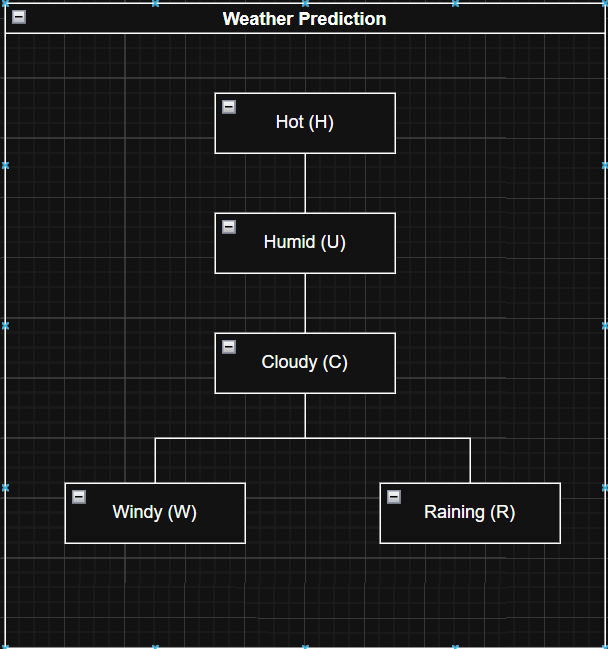


In [10]:
network = {
    'H': {'parents': [], 'children': ['U']},
    'U': {'parents': ['H'], 'children': ['C']},
    'C': {'parents': ['U'], 'children': ['R', 'W']},
    'R': {'parents': ['C'], 'children': []},
    'W': {'parents': ['C'], 'children': []},
}

print("The parents of node C are", network['C']['parents'])

prob = {
    'H': {
        (): {True: 0.5, False: 0.5}
    },
    'U': {
        (True,): {True: 0.7, False: 0.3},
        (False,): {True: 0.4, False: 0.6}
    },
    'C': {
        (True,): {True: 0.8, False: 0.2},
        (False,): {True: 0.3, False: 0.7}
    },
    'R': {
        (True,): {True: 0.6, False: 0.4},
        (False,): {True: 0.1, False: 0.9}
    },
    'W': {
        (True,): {True: 0.4, False: 0.6},
        (False,): {True: 0.2, False: 0.8}
    }
}


The parents of node C are ['U']


Hot ⊥ Cloudy | Humid: Temperature affects clouds only via humidity; given humidity, temperature adds no information on cloudiness.
Hot ⊥ Raining | Humid: Temperature's influence on rain is mediated by humidity and clouds; conditioned on humidity, it's independent of rain.
Hot ⊥ Windy | Humid: Wind depends on clouds from humidity, influenced by temperature; given humidity, temperature doesn't affect windiness.
Humid ⊥ Raining | Cloudy: Humidity impacts rain solely through clouds; given cloud status, humidity provides no extra rain insight.
Humid ⊥ Windy | Cloudy: Humidity's wind effect is indirect via clouds; conditioned on clouds, they're independent.
Raining ⊥ Windy | Cloudy: Rain and wind are separate cloud outcomes; given cloudiness, one doesn't affect the other's probability.

## Question 2.2

Now it's time to do inference on your network! You will implement the enumeration algorithm in the `infer()` function below. You may define additional helper functions as needed. Two examples of calling the `infer()` function for the network above would be:

```python
print("P(D=True | B=True)")
result = infer('D', True, {'B': True})

print("P(B=True) - no evidence")
result = infer('B', True, {})
```

In [12]:
all_vars_set = {'H', 'U', 'C', 'R', 'W'}

# Computes joint probability for a complete variable assignment
def get_prob(assignment):
    probability = 1.0
    for variable in all_vars_set:
        # Get parents from network
        parent_list = network[variable]['parents']
        parent_values = ()  
        # If there are parents, collect their values
        if parent_list:  
            parent_values_list = []
            for parent in parent_list:
                parent_values_list.append(assignment[parent])
            parent_values = tuple(parent_values_list)
        # Get the value for this variable
        current_value = assignment[variable]
        # Multiply by the probability from the prob table
        probability *= prob[variable][parent_values][current_value]
    return probability

# Recursively sums probs over hidden vars
def enumerate_sum(current_assignment, hidden_vars_left):
    if len(hidden_vars_left) == 0:  
        return get_prob(current_assignment)
    total_prob = 0.0
    # Pick the first hidden variable
    next_var = hidden_vars_left[0]
    # Try both True and False for it
    for value in [True, False]:
        # Copy assignment and add new value
        new_assignment = {}
        for key in current_assignment:
            new_assignment[key] = current_assignment[key]
        new_assignment[next_var] = value
        # Recurse on remaining vars
        total_prob += enumerate_sum(new_assignment, hidden_vars_left[1:])
    return total_prob

def infer(query_var, query_val, evidence):
    """
    Compute P(query_var=query_val | evidence)
    evidence: dict of {var: value} pairs
    """
    # 1. Enumerate all possible assignments to non-evidence variables
    # 2. Sum joint probabilities where query_var=query_val
    # 3. Normalize by sum over all values of query_var

    # Find hidden vars
    hidden = []
    for var in all_vars_set:
        if var != query_var and var not in evidence:
            hidden.append(var)

    # Calculate for when query is True
    assign_true = {}
    for k in evidence:
        assign_true[k] = evidence[k]
    assign_true[query_var] = True
    prob_true = enumerate_sum(assign_true, hidden)
    
    # Calculate for when query is False
    assign_false = {}
    for k in evidence:
        assign_false[k] = evidence[k]
    assign_false[query_var] = False
    prob_false = enumerate_sum(assign_false, hidden)
    
    # Normalize
    total = prob_true + prob_false
    if total == 0:
        return 0.0
    else:
        if query_val:
            return prob_true / total
        else:
            return prob_false / total

print("P(C=True)")
result = infer('C', True, {})
print(result)

print("P(R=True | H=True)")
result = infer('R', True, {'H': True})
print(result)


P(C=True)
0.575
P(R=True | H=True)
0.425


## Question 2.3

Finally, you will test your algorithm with three different queries. For each query, calculate the expected result by hand and call your `infer()` function to see if you get the same values.

*Note:* There may be some small differences due to the way decimals are represented on your computer.

Query 1: P(C=True)

P(C=True) = P(H=True) × [P(U=True|H=True) × P(C=True|U=True) + P(U=False|H=True) × P(C=True|U=False)] + P(H=False) × [P(U=True|H=False) × P(C=True|U=True) + P(U=False|H=False) × P(C=True|U=False)]

= 0.5 × (0.7 × 0.8 + 0.3 × 0.3) + 0.5 × (0.4 × 0.8 + 0.6 × 0.3)

= 0.5 × (0.56 + 0.09) + 0.5 × (0.32 + 0.18)

= 0.5 × 0.65 + 0.5 × 0.5

= 0.325 + 0.25 = 0.575

Query 2: P(R=True | H=True)

P(R=True, H=True) = sum_{U,C} P(H=True) × P(U|H=True) × P(C|U) × P(R=True|C)

= 0.5 × [0.7 × 0.8 × 0.6 + 0.7 × 0.2 × 0.1 + 0.3 × 0.3 × 0.6 + 0.3 × 0.7 × 0.1]

= 0.5 × [0.336 + 0.014 + 0.054 + 0.021]

= 0.5 × 0.425 = 0.2125

P(H=True) = 0.5

P(R=True | H=True) = 0.2125 / 0.5 = 0.425


Has the same results as function infer()

# Extra Credit

For up to 10 extra credit points, write some code that will do one regression step of the backward planning problem. The inputs of the problem would be (1) the representation of the goal state and (2) an action schema. The output of the problem would be the possible state of the world before doing the action schema. You can choose what data structures to use here.

*Note:* It's easy to ask an AI to do this for you and just paste it in. I will not accept a block of code without any other information. Think about what you can add here that proves you thought about and understand this problem.

You may also write this out by hand for a few points!